# CIMCYC session 26/11: time-series decoding workshop

Example of an easy time-series decoding pipeline using MNE. The data used were part of Ramírez-Haro et al. (2026) and are available online at https://openneuro.org/datasets/ds009134 <br>
This notebook was used as part of the EEG CIMCYC sessions<br><br>


Created on Mon 24 Nov 2026 <br>
**@author:** Almudena Ramírez Haro

## Setting up

Run following cell and restart environment to use MNE package. This only needs to be done once, you can comment the cell afterwards.




In [ ]:
!pip install mne

Now execute the cells below to initialise the notebook environment and import the relevant libraries

In [ ]:
from google.colab import drive
import mne
import os

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#sklearn libraries
from sklearn.pipeline import make_pipeline #applies transformations in brackets
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

#mne libraries
import mne
from mne.decoding import (
    SlidingEstimator,
    cross_val_multiscore
)

In [ ]:
datapath = '/content/drive/MyDrive/Colab Notebooks/decoding_session'

# 1. Data and experiment design

## 1.1 Experiment and stimuli

Experiment design:


*   Passive viewing: task was orthogonal and we disregard it
*   24 sequences with all the stimuli in one sequence, so each stimuli was seen 24 times.
*  This experiment has a couple of conditions that we will ignore now, so we are only using stimuli with full objects *in front* of the Kanizsa figure
*  The stimuli was divided into supraordinate (biological and artificial) and ordinate (vehicles vs insects vs clothing) categories, objects (cars vs ants vs hats) and exemplars (car1 vs car2 vs car3). Here we are only analysing the supraordinate category and objects.
*  Each image with front object was presented 24 times in total (considering all conditions)


![exp objects](https://drive.google.com/uc?id=1zeImvFLvze0ZzIAGn6Y8DFRfgvoNusXf)



The stimuli we are going to use will look like these. The conditions we are using here are bold in the stimulus name


![stim](https://drive.google.com/uc?id=1h35RjGbE2oQzEOP32B209LYrKSWRqRVL)



## 1.2. File structure following BIDS



<pre>
decoding_project/
├── derivatives/
│   ├── mne/
│   │   └── sub-{subject_number}_mne_epo.fif  #preprocessed and epoched EEG data per participant
│   └── results/
│       └── [decoding outputs in .csv format]
│       └── [figure outputs in .png format]
│
└── sub-{subject_number}/ #BIDS format
    └── eeg/
        ├── sub-{subject_number}_task-name.bdf  #raw EEG data, before preprocessing (not used)
        └── sub-{subject_number}_task-name.tsv  #behavioural input file in BIDS format
</pre>

# 2. Decoding example with one participant

## 2.1. Shaping the data

In [ ]:
subject_number = '05' #could also include in a loop to iterate through all subjects

eeg_filename = f'{datapath}/derivatives/mne/sub-{subject_number}_mne_epo.fif'
behav_filename = f'{datapath}/derivatives/mne/sub-{subject_number}_task-detection_events.tsv'

figure_filename = f'{datapath}/derivatives/decoding-outputs/sub-{subject_number}_bio.png'

In the following cells we:


1.   Use MNE to read the epochs from the EEG file. Here, the epochs are already preprocessed (-100 to 1000ms)
2.   Clean the tsv file by dropping the target trials, since this is a passive viewing experiment and the targets were orthogonal. Here we are also getting the stimuli with the full objects in front.
3.  For each stimulus we are going to analyse, we get the epoch of the neural data in which it was presented

![labels](https://drive.google.com/uc?id=104cXdY0va0AHEabDB0_ZzUoMZBWe57n7)

In [ ]:
#1. extract epochs
epochs = mne.read_epochs(eeg_filename)

#2. clean stimuli presentation file
full_behav_df = pd.read_csv(behav_filename,delimiter='\t')
clean_behav_df = full_behav_df.loc[
    ~full_behav_df['istarget'] &
    full_behav_df['stimpath'].str.contains('_front_', na=False)]

#3. align neural epoched data with stimuli presentation
eeg_df = epochs.get_data()[clean_behav_df.index,:,:]
analysis_df = pd.DataFrame({'time':epochs.times})  #new DF with a column 'time' extracted from epochs.times (time vector in seconds)

Reading /content/drive/MyDrive/Colab Notebooks/decoding_session/derivatives/mne/sub-05_mne_epo.fif ...
    Found the data of interest:
        t =    -100.00 ...     799.00 ms
        0 CTF compensation matrices available
Not setting metadata
4475 matching events found
No baseline correction applied
0 projection items activated


## 2.2. Decoding

We are using LDA to decode:


*   Biological category (biological vs artificial)-> 1/2 chance
*   Objects (cars vs insects vs flowers etc)-> 1/30 chance



### 2.2.1 Biological classification

Step by step:

#### 1.   Get the label to predict (being biological vs artificial)


![ ](https://drive.google.com/uc?id=14zHty3vXIYq6dgWMbZovl2KolmBK9pCh)

In [ ]:
#1. getting the stimuli
bio_y = ['_bio_' in x for x in clean_behav_df['stimpath']] #boolean values




#### 2.   Identify the test and train groups




Here, we separate per block number, as all the stimuli were presented once per block. That means

  ![ ](https://drive.google.com/uc?id=14TJa52KCOS2QdTZ-P7hG3_Ugz_cpQai6)

In [ ]:
#2. getting test and train groups
groups = np.array(clean_behav_df['blocksequencenumber'])

####  3. Create the classifier

We are using a linear classifier (LDA)

We have to specify the class prior probabilities: 1/n, being *n* the number of unique labels we are decoding (here it is 2)


In [ ]:
#3.
classifier_LDA = make_pipeline(LinearDiscriminantAnalysis(priors=np.array([(1/2), (1/2)]))) #pipeline with LDA, chance level is 1/2 because we are decoding 2 categories


 #### 4. Fit the classifier on each time point




We will use a sliding estimator to fit, predict and score a series of models to each subset of the dataset along the last dimension. Performs a sliding window estimation to decode the temporal patterns.

  **Parameters of mne.decoding.SlidingEstimator:** (base_estimator, scoring=None, n_jobs=None, *, position=0, allow_2d=False, verbose=None)
  * <u>base_estimator</u>: pipeline defined before with LDA (*classifier_LDA*)
  * <u>scoring</u>: loss function to use during cross-validation ('balanced_accuracy')
  * <u>n_jobs</u>: number of jobs to run in parallel.  
  * position: position for the progress bar.
  * allow_2d: if True, allow 2D data as input
  * <u>verbose</u>: level of detail of the output message. If set as '0' it suppresses the output verbosity, so we won't see detailed progress messages during the computation

In [ ]:
#4.
time_decoding = SlidingEstimator(classifier_LDA, n_jobs=1, scoring='balanced_accuracy', verbose=0)

####  5. Cross-validation

A common way to assess the classifier’s generalisation
performance is cross-validation.

We will apply the classifier to the data based on the train and test groups we formed previously, following a Leave One Out strategy

**Parameters of mne.decoding.cross_val_multiscore:** (estimator, X, y=None, groups=None, scoring=None, cv=None, n_jobs=None, verbose=None, fit_params=None, pre_dispatch='2*n_jobs')
* <u>estimator</u>: object used to fit the data. We use *time_decoding*
* <u>X</u>: the data to fit (*eeg_df*)
* <u>y</u>: target variable to predict (*bio_y*)
* <u>groups</u>: groups labels for the samples used (*groups*)
* scoring: (when using an estimator which inherently returns multidimensional output - in particular, SlidingEstimator or GeneralizingEstimator - you should set the scorer there, not here)
* <u>cv</u>: cross-validation splitting strategy (*Leave One Group Out cross-validator*)
* fit_params: parameters to pass to the fit method of the estimator
* pre_dispatch: Controls the number of jobs that get dispatched during parallel execution.

In [ ]:
#5.
scores = cross_val_multiscore(time_decoding, eeg_df, bio_y, groups=groups, cv=LeaveOneGroupOut(), n_jobs=1)


  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

... (2 outputs left out)

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

#### 6. Getting the results!

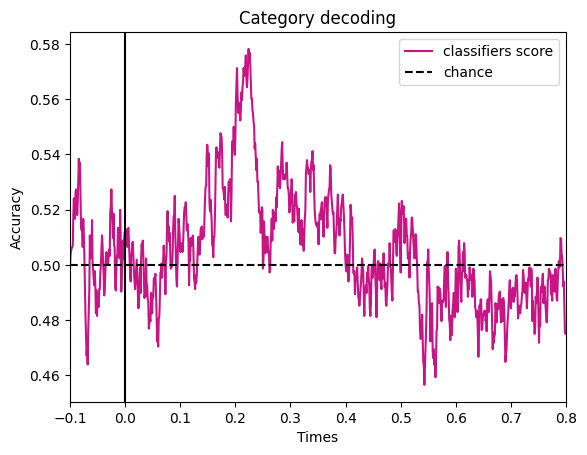

In [ ]:
analysis_df['animacy_decoding'] = np.mean(scores, axis=0) #mean scores across cross-validation splits

fig, ax = plt.subplots()
ax.plot(epochs.times, analysis_df['animacy_decoding'], color='mediumvioletred', label='classifiers score')
ax.axhline(1/2, color='k', linestyle='--', label='chance') #if we are decoding more than 2 categories, change to '1/n'
ax.set_xlabel('Times')
ax.set_ylabel('Accuracy')
ax.legend()
ax.axvline(0.0, color='k', linestyle='-')
ax.set_title('Category decoding')
ax.set_xlim(-0.1, 0.8)

fig.savefig(figure_filename)


output_filename = f'{datapath}/derivatives/decoding-outputs/sub-{subject_number}_bio_results.csv'
analysis_df.to_csv(output_filename, index=False)

### 2.2.2 Object classification

The different things here are:
* the way we get the y labels (in this case it's easier using the numerical code in the stimulus' name)
* that chance level is 1/33 (there are 33 different objects)


In [ ]:
#1. getting the labels
object_y = [int(x[5:8]) for x in clean_behav_df['stimpath']]

#2. separating train and test groups by trials
groups = np.array(clean_behav_df['blocksequencenumber'])

In [ ]:
#3. creating the classifier using priors based on unique labels
classifier_LDA = make_pipeline(LinearDiscriminantAnalysis(priors=(1+0*np.unique(object_y))/len(np.unique(object_y))))


In [ ]:
#4. sliding estimator
time_decoding = SlidingEstimator(classifier_LDA, n_jobs=1, scoring='balanced_accuracy', verbose=0)

In [ ]:
#5. getting cross-validation scores
scores = cross_val_multiscore(time_decoding, eeg_df, object_y, groups=groups, cv=LeaveOneGroupOut(), n_jobs=1)


  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

... (2 outputs left out)

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

  0%|          | Fitting SlidingEstimator : 0/900 [00:00<?,       ?it/s]

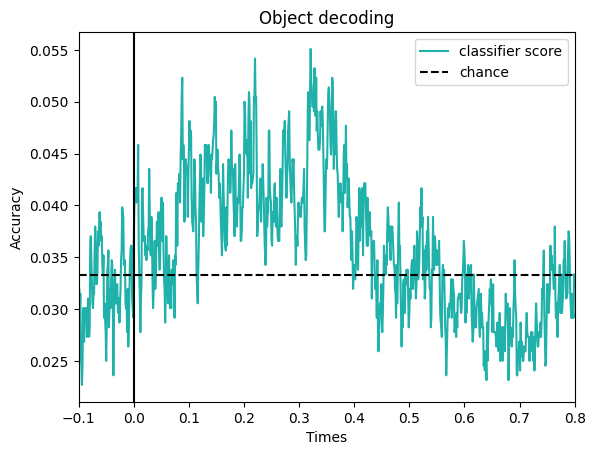

In [ ]:
#Results!

analysis_df['object_decoding'] = np.mean(scores, axis=0) #mean scores across cross-validation splits


fig, ax = plt.subplots()
ax.plot(epochs.times, analysis_df['object_decoding'], color='lightseagreen', label='classifier score')
ax.axhline(1/len(np.unique(object_y)), color='k', linestyle='--', label='chance')
ax.set_xlabel('Times')
ax.set_ylabel('Accuracy')
ax.legend()
ax.axvline(0.0, color='k', linestyle='-')
ax.set_title('Object decoding')
ax.set_xlim(-0.1, 0.8)

obj_fig_filename = f'{datapath}/derivatives/decoding-outputs/sub-{subject_number}_obj.png'
fig.savefig(obj_fig_filename)

output_filename = f'{datapath}/derivatives/decoding-outputs/sub-{subject_number}_obj_results.csv'
analysis_df.to_csv(output_filename, index=False)

# 3. Decoding pipeline with more participants

In [ ]:
#I would run this in a separate python file

def run_decoding(subjectnr, decode, overwrite=0):
  '''
  Run decoding analysis on a single subject
  '''
  eeg_filename = f'{datapath}/derivatives/mne/sub-{subjectnr}_mne_epo.fif'
  behav_filename = f'{datapath}/derivatives/mne/sub-{subjectnr}_task-detection_events.tsv'
  output_filename = f'{datapath}/derivatives/decoding-outputs/sub-{subjectnr}_results.csv'

  figure_fn = f'{datapath}/derivatives/results/figures/sub-{subjectnr}_.png'

  if os.path.exists(eeg_filename) and os.path.exists(behav_filename):

        if os.path.exists(output_filename) and not overwrite:
          print('file exists:', output_filename)
          return

        else:
          ## Shaping data
          #1. extract epochs
          epochs = mne.read_epochs(eeg_filename)

          #2. clean stimuli presentation file
          full_behav_df = pd.read_csv(behav_filename,delimiter='\t')
          clean_behav_df = full_behav_df.loc[
              ~full_behav_df['istarget'] &
              full_behav_df['stimpath'].str.contains('_front_', na=False)]

          #3. align neural epoched data with stimuli presentation
          eeg_df = epochs.get_data()[clean_behav_df.index,:,:]
          analysis_df = pd.DataFrame({'time':epochs.times})

          ## Decoding
          #1.
          if decode == 'biological':
            y = ['_bio_' in x for x in clean_behav_df['stimpath']]
            decode_label = 'bio'

          if decode == 'object':
            y = [int(x[5:8]) for x in clean_behav_df['stimpath']]
            decode_label = 'object'

          #2.getting the labels
          groups = np.array(clean_behav_df['blocksequencenumber'])

          #3. creating the classifier using priors based on unique labels
          classifier_LDA = make_pipeline(LinearDiscriminantAnalysis(priors=(1+0*np.unique(y))/len(np.unique(y))))

          #4. sliding estimator
          time_decoding = SlidingEstimator(classifier_LDA, n_jobs=1, scoring='balanced_accuracy', verbose=0)


          #5. getting cross-validation scores
          scores = cross_val_multiscore(time_decoding, eeg_df,
                                        y, groups=groups, cv=LeaveOneGroupOut(), n_jobs=1)


          #Results!

          analysis_df[f'{decode}_decoding'] = np.mean(scores, axis=0) #mean scores across cross-validation splits

          fig, ax = plt.subplots()
          ax.plot(epochs.times, analysis_df[f'{decode}_decoding'], label=decode_label)
          ax.axhline(1/len(np.unique(y)), color='k', linestyle='--', label='chance')
          ax.set_xlabel('Time (s) relative to stimulus onset')
          ax.set_ylabel('Accuracy')
          ax.legend()
          ax.axvline(0.0, color='k', linestyle='-')
          ax.set_title(f'{decode} decoding')
          ax.set_xlim(-0.1, 0.8)
          fig.savefig(figure_fn)


          analysis_df.to_csv(output_filename, index=False)

        print(f'Participant {subjectnr} decoded!')


In [ ]:
for participant in range(3,10):
  try:
    run_decoding('%02i' % participant, 'biological', 0)
  except Exception as e:
    print(e)

### Mean across participants

TODO: check object baseline before sharing!!!! (ppts 05 and 08 might have been overwritten)

In [ ]:
ppts_decoding_df = pd.DataFrame({'time':epochs.times})

#everything in the same df makes it easier to manipulate for other analyses
for subjectnr in range(0,10):
  subjectnr = '%02i'%subjectnr
  bio_infn = f'{datapath}/derivatives/decoding-outputs/sub-{subjectnr}_bio_results.csv'
  obj_infn = f'{datapath}/derivatives/decoding-outputs/sub-{subjectnr}_obj_results.csv'

  if os.path.exists(bio_infn) and os.path.exists(obj_infn):
    subject_bio_df = pd.read_csv(bio_infn)
    ppts_decoding_df[f'{subjectnr}-animacy'] = subject_bio_df['animacy_decoding']

    subject_obj_df = pd.read_csv(obj_infn)
    ppts_decoding_df[f'{subjectnr}-object'] = subject_obj_df['object_decoding']


In [ ]:
decoding_list = ['animacy', 'object']
subjectnr = ['03', '05', '08', '09'] #it's not nice to hardcode things but it was faster

#smoothing (rolling window=10)
smoothing_df = pd.DataFrame({'time': epochs.times})
animacy_allppts = []
objects_allppts = []
for ppt in subjectnr:
  smoothing_df[f'{ppt}-animacy'] = pd.Series(ppts_decoding_df[f'{ppt}-animacy']).rolling(window=10, min_periods=1, center=True).mean()
  smoothing_df[f'{ppt}-object'] = pd.Series(ppts_decoding_df[f'{ppt}-object']).rolling(window=10, min_periods=1, center=True).mean()

  animacy_allppts.append(smoothing_df[f'{ppt}-animacy'])
  objects_allppts.append(smoothing_df[f'{ppt}-object'])


#mean scores across all participants
means_df = pd.DataFrame({'time': epochs.times})
means_df['animacy'] = np.mean(np.array(animacy_allppts).T,axis=1)
means_df['object'] = np.mean(np.array(objects_allppts).T,axis=1)


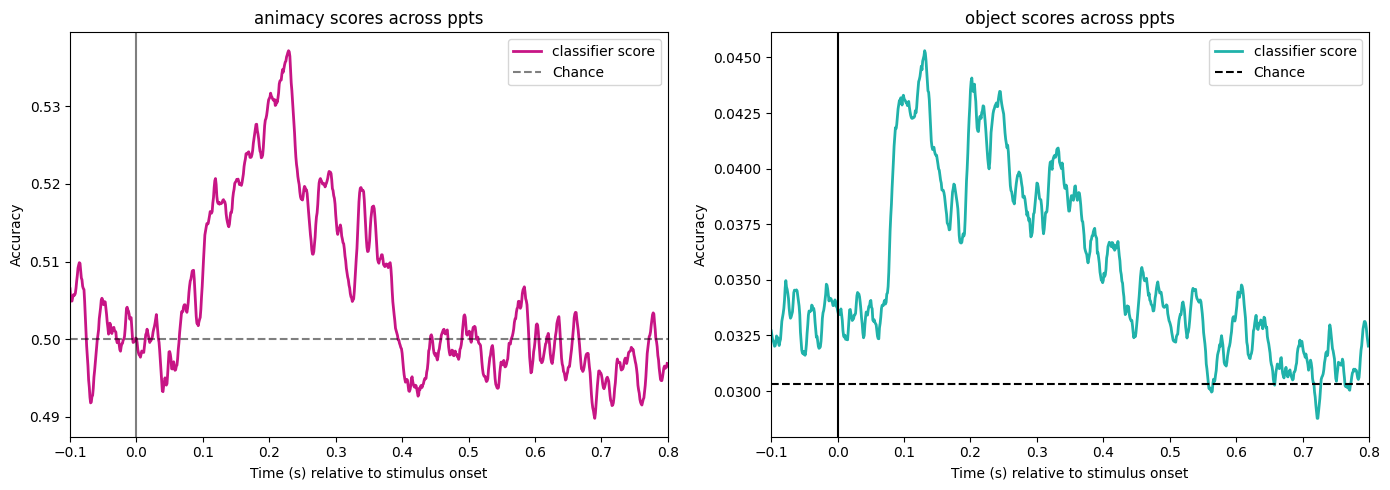

In [ ]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

#plots for animacy!
ax1.plot(means_df['time'], means_df['animacy'], color='mediumvioletred', label='classifier score', linewidth=2)
ax1.axhline(1/2, color='k', linestyle='--', alpha=0.5, label='Chance')
ax1.axvline(0.0, color='k', linestyle='-', alpha=0.5)
ax1.set_xlabel('Time (s) relative to stimulus onset')
ax1.set_ylabel('Accuracy')
ax1.set_title('animacy scores across ppts')
ax1.legend()
ax1.set_xlim(-0.1, 0.8)

#plot for objects!
ax2.plot(means_df['time'], means_df['object'], color = 'lightseagreen', label='classifier score', linewidth=2)
ax2.axhline(1/33, color='k', linestyle='--',label='Chance')
ax2.axvline(0.0, color='k', linestyle='-')
ax2.set_xlabel('Time (s) relative to stimulus onset')
ax2.set_ylabel('Accuracy')
ax2.set_title('object scores across ppts')
ax2.legend()
ax2.set_xlim(-0.1, 0.8)


plt.tight_layout()
plt.show()

# TODO 4. Decoding outputs: accuracy vs prediction

# 5. Crossdecoding

Can be useful to check if the decodable information found in the brain during one condition generalises to other stimuli or conditions. The classifier would be trained on neural data during the control condition and be tested on unlabelled data from another condition. For example:
![ ](https://drive.google.com/uc?id=1QU9JUyYtnouwRIY0LDUVFd0DFGPZpNj8)

In our case, we can cross-decode the identity of the objects training on the information of two exemplars and testing on the third one:

![ ](https://drive.google.com/uc?id=1N8LlxhM9XOt59RCZwh3qc5k0UosWKKsn)

In our code, this would look like:




In [ ]:
#1. getting the labels
bio_y = ['_bio_' in x for x in clean_behav_df['stimpath']] #boolean values
bio_y = np.array(bio_y)


In [ ]:
#2. separating train and test groups
##2.1 mask the stimuli/conditions we are using for each
clean_behav_df['train'] = 0
train_mask = clean_behav_df['stimpath'].str[5:9].str[-1] != '3' #we are using exemplars now so we go all the way until the last digit
clean_behav_df.loc[train_mask, 'train'] = 1


/tmp/ipykernel_11245/2642382690.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_behav_df['train'] = 0


In [ ]:
clean_behav_df

,onset,duration,onsetsample,eventnumber,subjectnr,eventnumber.1,blocksequencenumber,sequencenumber,presentation_number,stimpath,istarget,time_stimon,time_stimoff,stimduration,train
2,45.318848,0.2,92813,2,8,2,0,0,2,stim\0512110_artif_car2_front_invalid_triangle...,0,51.924378,52.116044,0.191667,1
6,46.943848,0.2,96141,6,8,6,0,0,6,stim\1313101_bio_sunflower3_front_valid_square...,0,53.549408,53.741075,0.191667,0
7,47.343750,0.2,96960,7,8,7,0,0,7,stim\1312101_bio_sunflower2_front_valid_square...,0,53.949373,54.141040,0.191667,1
8,47.743652,0.2,97779,8,8,8,0,0,8,stim\0123111_artif_hat3_front_invalid_square.png,0,54.349381,54.541048,0.191667,0
10,48.543945,0.2,99418,10,8,10,0,0,10,stim\1433111_bio_butterfly3_front_invalid_squa...,0,55.149369,55.341036,0.191667,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4450,2511.829590,0.2,5144227,4450,8,4450,11,23,360,stim\1531110_bio_kangaroo1_front_invalid_trian...,0,2518.475488,2518.667154,0.191667,1
4453,2513.029297,0.2,5146684,4453,8,4453,11,23,363,stim\1223111_bio_peacock3_front_invalid_square...,0,2519.675414,2519.867081,0.191667,0
4454,2513.429199,0.2,5147503,4454,8,4454,11,23,364,stim\0113101_artif_glasses3_front_valid_square...,0,2520.075408,2520.267075,0.191667,0
4458,2515.029297,0.2,5150780,4458,8,4458,11,23,368,stim\1311110_bio_sunflower1_front_invalid_tria...,0,2521.675417,2521.867084,0.191667,1


In [ ]:
crossdecoding_df = pd.DataFrame({'time': epochs.times})

In [ ]:
#now for each sequence number, we separate the decoding by our train and test conditions
for i in np.unique(clean_behav_df['sequencenumber']):
            train_indices = (clean_behav_df['sequencenumber'] != i) & (clean_behav_df['train'] == 1)
            test_indices = (clean_behav_df['sequencenumber'] == i) & (clean_behav_df['train'] == 0)
            train_indices = np.asarray(train_indices)
            test_indices = np.asarray(test_indices)

            eeg_train = eeg_df[train_indices]
            y_train = bio_y[train_indices]


            clf = make_pipeline(LinearDiscriminantAnalysis(priors=[.5,.5]))
            time_decod = SlidingEstimator(clf, n_jobs=1, scoring='balanced_accuracy', verbose=0)
            time_decod.fit(eeg_train, y_train)

            y_test  = object_y[test_indices] #used for the scores

            predict = time_decod.predict(eeg_df[test_indices])
            crossdecoding_df[f'object_decoding_{i}'] = predict.mean(axis=0) #getting mean over trials


In [ ]:
crossdecoding_df[f'mean'] = crossdecoding_df[[col for col in crossdecoding_df.columns]].mean(axis=1)

In [ ]:
crossdecoding_df

,time,object_decoding_0,object_decoding_1,object_decoding_2,object_decoding_3,object_decoding_4,object_decoding_5,object_decoding_6,object_decoding_7,object_decoding_8,...,object_decoding_15,object_decoding_16,object_decoding_17,object_decoding_18,object_decoding_19,object_decoding_20,object_decoding_21,object_decoding_22,object_decoding_23,mean
0,-0.100,0.548387,0.551724,0.482759,0.387097,0.346154,0.617647,0.515152,0.518519,0.605263,...,0.482759,0.333333,0.566667,0.580645,0.551724,0.607143,0.56250,0.400000,0.72,0.492796
1,-0.099,0.516129,0.482759,0.517241,0.516129,0.423077,0.588235,0.484848,0.481481,0.578947,...,0.517241,0.433333,0.500000,0.548387,0.448276,0.571429,0.46875,0.400000,0.60,0.476389
2,-0.098,0.483871,0.482759,0.482759,0.516129,0.384615,0.558824,0.454545,0.407407,0.526316,...,0.517241,0.466667,0.466667,0.548387,0.448276,0.642857,0.56250,0.371429,0.52,0.469334
3,-0.097,0.548387,0.448276,0.448276,0.451613,0.384615,0.588235,0.515152,0.407407,0.526316,...,0.482759,0.500000,0.433333,0.548387,0.413793,0.535714,0.46875,0.342857,0.48,0.455184
4,-0.096,0.516129,0.448276,0.551724,0.516129,0.346154,0.558824,0.484848,0.407407,0.605263,...,0.482759,0.500000,0.400000,0.548387,0.413793,0.500000,0.50000,0.342857,0.48,0.452293
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,0.795,0.451613,0.482759,0.620690,0.580645,0.423077,0.588235,0.666667,0.555556,0.473684,...,0.551724,0.533333,0.466667,0.548387,0.310345,0.500000,0.37500,0.371429,0.40,0.522104
896,0.796,0.419355,0.482759,0.551724,0.645161,0.461538,0.617647,0.636364,0.481481,0.500000,...,0.551724,0.566667,0.466667,0.516129,0.379310,0.535714,0.34375,0.400000,0.36,0.509250
897,0.797,0.419355,0.482759,0.517241,0.677419,0.423077,0.647059,0.636364,0.481481,0.447368,...,0.551724,0.600000,0.466667,0.516129,0.379310,0.464286,0.34375,0.400000,0.40,0.514845
898,0.798,0.419355,0.482759,0.517241,0.709677,0.500000,0.647059,0.575758,0.518519,0.473684,...,0.551724,0.600000,0.433333,0.548387,0.379310,0.464286,0.31250,0.400000,0.40,0.518204


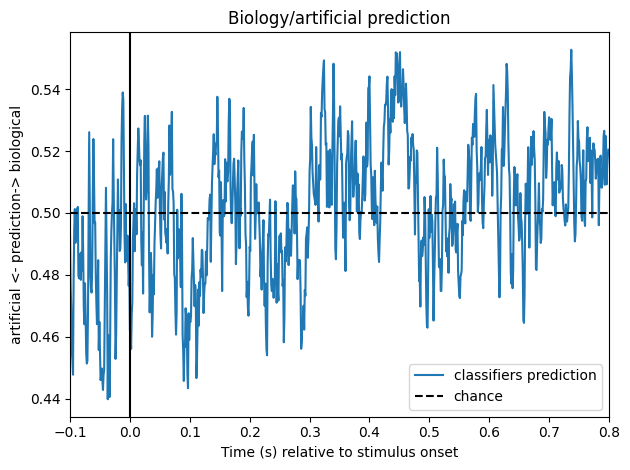

In [ ]:
fig, ax = plt.subplots()
ax.plot(epochs.times, crossdecoding_df['mean'], label='classifiers prediction')
ax.axhline(1/2, color='k', linestyle='--', label='chance')
ax.set_xlabel('Time (s) relative to stimulus onset')
ax.set_ylabel('artificial <- prediction-> biological')
ax.legend()
ax.axvline(0.0, color='k', linestyle='-')
ax.set_title('Biology/artificial prediction')
ax.set_xlim(-0.1, 0.8)

plt.tight_layout()
plt.show()

Not great prediction in our case because the design was not done for that

# 6. What happens after decoding?

Stats on the classifier's scores depending on our experimental hypotheses

![link text](https://drive.google.com/uc?id=1vyKdSQ3EGvzAYMWZN4QevIh3GRZcilzw)

(Taken from Teichmann et al., 2017)

Additional multivariate pattern analyses

![analyses](https://drive.google.com/uc?id=1GrpCiVWKtVcY0B9rJ5kN8CgBByL04diz)
(Taken from Grootswagers et al., 2017)

# 7. Resources

Time-series decoding:
* Grootswagers, T., Wardle, S. G., & Carlson, T. A. (2017). Decoding Dynamic Brain
Patterns from Evoked Responses: A Tutorial on Multivariate Pattern Analysis
Applied to Time Series Neuroimaging Data. Journal of Cognitive Neuroscience,
29(4), 677–697. https://doi.org/10.1162/jocn_a_01068

* Cichy, R. M., & Pantazis, D. (2017). Multivariate pattern analysis of MEG and EEG: A comparison of representational structure in time and space. NeuroImage, 158, 441–454. https://doi.org/10.1016/j.neuroimage.2017.07.023
* Contini, E. W., Wardle, S. G., & Carlson, T. A. (2017). Decoding the time-course of object
recognition in the human brain: From visual features to categorical decisions.
Neuropsychologia, Special Issue: Concepts, Actions and Objects: Functional
and Neural Perspectives, 105, 165–176.
https://doi.org/10.1016/j.neuropsychologia.2017.02.013


MVPA in general:
* Hebart, M. N., & Baker, C. I. (2018). Deconstructing multivariate decoding for the study
of brain function. NeuroImage, New Advances in Encoding and Decoding of Brain
Signals, 180, 4–18. https://doi.org/10.1016/j.neuroimage.2017.08.005
* Carlson, T. A., Schrater, P., & He, S. (2003). Patterns of Activity in the Categorical Representations of Objects.


On classifiers:
* Misaki, M., Kim, Y., Bandettini, P. A., & Kriegeskorte, N. (2010). Comparison of
multivariate classifiers and response normalizations for pattern-information
fMRI. NeuroImage, 53(1), 103–118.
https://doi.org/10.1016/j.neuroimage.2010.05.051



On visual decoding:
* Robinson, A. K., Quek, G. L., & Carlson, T. A. (2023). Visual Representations: Insights
from Neural Decoding. Annual Review of Vision Science, 9(1), null.
https://doi.org/10.1146/annurev-vision-100120-025301



Limitations:
* de-Wit, L., Alexander, D., Ekroll, V., & Wagemans, J. (2016). Is neuroimaging measuring
information in the brain? Psychonomic Bulletin & Review, 23(5), 1415–1428.
https://doi.org/10.3758/s13423-016-1002-0